# Model Monitoring: Population Stability Index (PSI)

Is the PD scorecard still valid for new applicants? This notebook compares the 2015 loans with the 2007-2014 loans the model was trained on.

**PSI** = Σ (actual % − expected % ) × ln(actual % / expected %), over the bins of a variable.

| PSI | Reading |
|---|---|
| < 0.10 | Stable, no action |
| 0.10 – 0.25 | Some shift, investigate |
| > 0.25 | Significant shift, consider redeveloping the model |

In [1]:
import sys
sys.path.append('../src/')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from utils import LogisticRegression_with_p_values
from preprocessing import (PD_FEATURES, general_preprocessing, add_pd_dummies,
                           pd_design_matrix)
from expected_loss import psi, psi_by_feature
sns.set()

## Expected population: 2007-2014 training loans

In [2]:
loan_data_inputs_train = pd.read_csv('../data/processed/loan_data_inputs_train.csv', index_col=0,
                                     usecols=lambda c: c in set(PD_FEATURES) | {'Unnamed: 0', 'mths_since_issue_d'},
                                     low_memory=False)
# FIX: the stored 'mths_since_issue_d:>84' column used range(85, max), which left out the oldest loans.
loan_data_inputs_train['mths_since_issue_d:>84'] = np.where(loan_data_inputs_train['mths_since_issue_d'] >= 85, 1, 0)
expected = pd_design_matrix(loan_data_inputs_train, with_ref_categories=True)
expected.shape

(349713, 101)

## Actual population: 2015 loans, preprocessed exactly like the training data

In [3]:
loan_data_2015 = pd.read_csv('../data/raw/loan_data_2015.csv', low_memory=False)
loan_data_2015 = add_pd_dummies(general_preprocessing(loan_data_2015))
actual = pd_design_matrix(loan_data_2015, with_ref_categories=True)
actual.shape

(421094, 101)

## Credit scores for both populations

In [4]:
df_scorecard = pd.read_csv('../data/processed/df_scorecard.csv', index_col=0)
scores = df_scorecard.set_index('Feature name')['Score - Final']
original_feature = df_scorecard.set_index('Feature name')['Original feature name'].drop('Intercept')

def credit_score(X):
    return scores['Intercept'] + X[scores.index.drop('Intercept')].to_numpy() @ scores.drop('Intercept').to_numpy()

expected_score = credit_score(expected)
actual_score = credit_score(actual)
pd.DataFrame({'2007-2014': pd.Series(expected_score).describe(),
              '2015': pd.Series(actual_score).describe()})

,2007-2014,2015
count,349713.000000,421094.000000
mean,582.546957,644.888300
std,64.254619,60.299735
min,361.000000,451.000000
25%,537.000000,599.000000
50%,579.000000,641.000000
75%,625.000000,694.000000
max,800.000000,812.000000


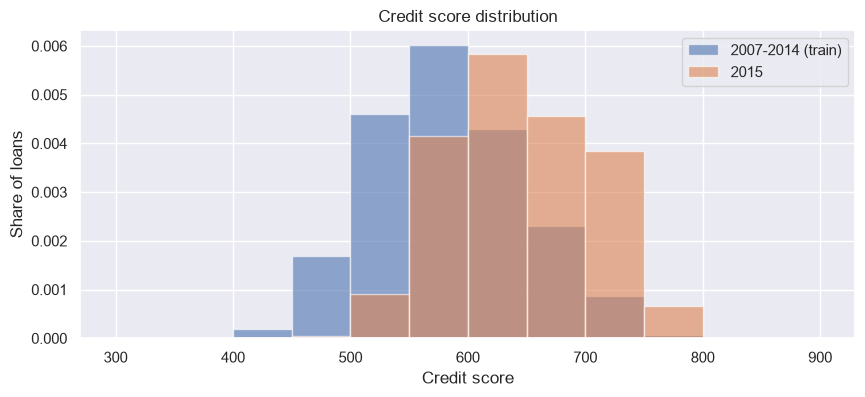

In [5]:
bins = np.arange(300, 901, 50)
plt.figure(figsize=(10, 4))
plt.hist(expected_score, bins=bins, alpha=0.6, density=True, label='2007-2014 (train)')
plt.hist(actual_score, bins=bins, alpha=0.6, density=True, label='2015')
plt.xlabel('Credit score'); plt.ylabel('Share of loans'); plt.legend()
plt.title('Credit score distribution');

In [6]:
expected_band = pd.cut(pd.Series(expected_score), bins, include_lowest=True).value_counts(normalize=True, sort=False)
actual_band = pd.cut(pd.Series(actual_score), bins, include_lowest=True).value_counts(normalize=True, sort=False)
psi_score = psi(expected_band, actual_band)
print(f'PSI of the credit score: {psi_score:.3f}')

PSI of the credit score: 1.123


## PSI by input variable

In [7]:
psi_features = psi_by_feature(expected, actual, original_feature)
psi_table = psi_features.to_frame()
psi_table['Reading'] = pd.cut(psi_table['PSI'], [-np.inf, 0.1, 0.25, np.inf],
                              labels=['Stable', 'Some shift', 'Significant shift'])
psi_table

,PSI,Reading
feature,,
mths_since_issue_d,13.392276,Significant shift
initial_list_status,0.335540,Significant shift
int_rate,0.079298,Stable
dti,0.078149,Stable
mths_since_last_record,0.056001,Stable
inq_last_6mths,0.053260,Stable
verification_status,0.048450,Stable
mths_since_earliest_cr_line,0.033411,Stable
term,0.013341,Stable


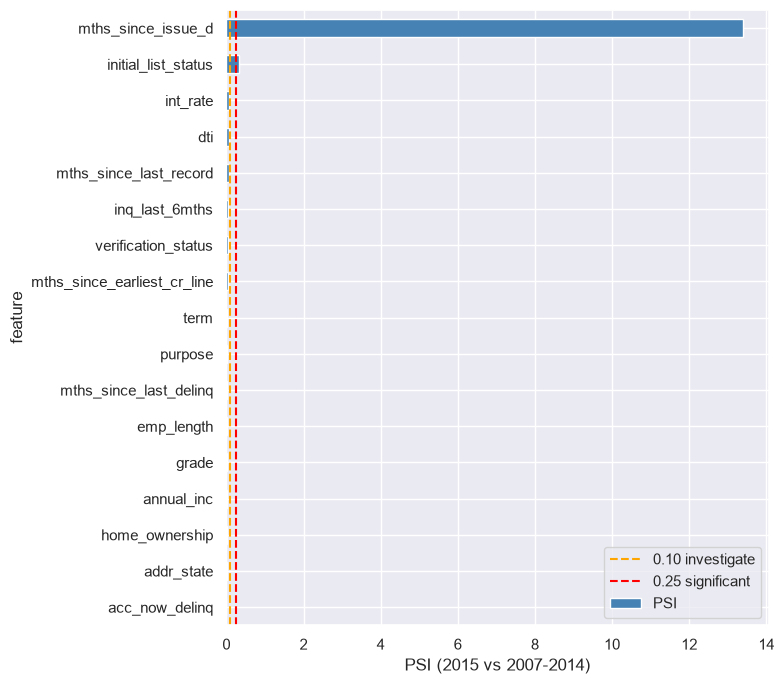

In [8]:
ax = psi_features.sort_values().plot(kind='barh', figsize=(8, 7), color='steelblue')
ax.axvline(0.10, color='orange', linestyle='--', label='0.10 investigate')
ax.axvline(0.25, color='red', linestyle='--', label='0.25 significant')
ax.set_xlabel('PSI (2015 vs 2007-2014)'); ax.legend(); plt.tight_layout()

## Predicted default rate

In [9]:
pd_model = joblib.load('../models/pd_model.sav')
pd_expected = pd_model.model.predict_proba(pd_design_matrix(loan_data_inputs_train).to_numpy())[:, 0]
pd_actual = pd_model.model.predict_proba(pd_design_matrix(loan_data_2015).to_numpy())[:, 0]
print(f'Mean predicted PD, 2007-2014: {pd_expected.mean():.2%}')
print(f'Mean predicted PD, 2015:      {pd_actual.mean():.2%}')

Mean predicted PD, 2007-2014: 10.97%
Mean predicted PD, 2015:      5.46%


In [10]:
psi_table.to_csv('../reports/psi_2015_vs_2007_2014.csv')

## Conclusion

- **The credit score has shifted significantly (PSI 1.12).** 2015 applicants score about 62 points higher on average (645 vs 583).
- **Most of that shift is structural, not a change in borrowers.** `mths_since_issue_d` (PSI 13.4) counts months to December 2017, so every 2015 loan falls in the youngest bin, which carries a large positive score. This also halves the mean predicted PD (5.5% vs 11.0%), which is an artefact, not a real improvement in credit quality.
- **`initial_list_status` shifted for real (PSI 0.34):** LendingClub moved most new loans from fractional (`f`) to whole-loan (`w`) listings.
- **Every borrower attribute is stable (PSI < 0.10):** grade, income, DTI, interest rate, employment length, purpose and state all look like the training population.

**Recommendation:** before scoring new loans, replace `mths_since_issue_d` with loan age measured at a fixed point (e.g. months on book at scoring time) or drop it, and re-estimate the `initial_list_status` effect on recent loans. The borrower variables do not require redeveloping the model.